<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/>

# From EDA To Preprocessing
---
<small>© COPYRIGHT 2026 DECODED LIMITED. ALL RIGHTS RESERVED. Web: https://decoded.com/ </small>

## Workshop Introduction

This workbook bridges exploratory data analysis and machine learning modelling by guiding you through the essential preprocessing pipeline. You will transform raw data into model-ready features whilst preventing common pitfalls like data leakage.

### Learning Objectives

* Understand and implement train-test splits with stratification to prevent data leakage
* Identify and remove unhelpful features (constants, derivatives, redundant information)
* Apply categorical encoding techniques (ordinal, one-hot) appropriate to feature semantics
* Use transformations (log, binning) to normalise skewed distributions and reduce outlier influence
* Standardise features to ensure fair model performance across all scales
* Validate preprocessing decisions through before/after distribution comparisons

### What You Will Learn

* **Data Leakage Prevention:** Why splitting before preprocessing is critical—and how stratification ensures representative train/test sets
* **Feature Inspection:** How to detect constant features, derivative relationships, and multicollinearity using correlation analysis
* **Categorical Encoding:** When to use ordinal encoding (ranked categories) versus one-hot encoding (nominal categories)
* **Transformations:** How log transforms and binning strategies improve feature distributions for model readiness
* **Standardisation:** Why scaling features to mean=0 and std=1 prevents certain models from being dominated by high-magnitude features
* **Professional Pipelines:** How to structure reusable, debuggable preprocessing code that works at scale

### Process: How will I learn this content?

##### Outline

- Group discussions
- Coding demos
- Coding challenges




# Machine Learning Preprocessing The Bridge Between EDA and Modelling

This notebook will work us through a short tour the additional steps that a Data Scientist to the preprare the data for modelling. As you we will see some the steps are driven by some of the plots we used earlier but, instead they now support a new chain of decisions.





##  Step 1: Data Creation & Problem Definition
Before we clean data, we have to understand it. We are looking at a **Loan Approval** scenario.
* **Target ($y$):** `Approved` (1 for Yes, 0 for No).
* **Features ($X$):** Income, Credit, and Property type.




# Loans Approval Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




np.random.seed(42)
n_samples = 100
income = np.random.lognormal(mean=8.5, sigma=0.7, size=n_samples).astype(int)
properties = np.random.choice(['Urban', 'Rural', 'Suburb'], size=n_samples)
credits = np.random.choice(['Poor', 'Fair', 'Good'], size=n_samples, p=[0.2, 0.3, 0.5])
loan_policy = ['POL_2024'] * n_samples
tax_paid = income * 0.15
approved = ((income > 6000) | (np.array(credits) == 'Good')).astype(int)
reliability_score = np.random.normal(loc=0.5, scale=0.1, size=n_samples)
reliability_score = np.clip(reliability_score, 0, 1) # Ensure strictly 0-1

df = pd.DataFrame({
    'Income': income,
    'Tax_Paid': tax_paid,
    'Reliability_Score': reliability_score, # The new contrast feature
    'Loan_Policy': loan_policy,
    'Property': properties,
    'Credit': credits,
    'Approved': approved
})


In [ ]:
df.head()

,Income,Tax_Paid,Reliability_Score,Loan_Policy,Property,Credit,Approved
0,6958,1043.70,0.358463,POL_2024,Urban,Fair,1
1,4461,669.15,0.457935,POL_2024,Rural,Good,1
2,7734,1160.10,0.465729,POL_2024,Urban,Good,1
3,14272,2140.80,0.419772,POL_2024,Urban,Fair,1
4,4171,625.65,0.483871,POL_2024,Suburb,Fair,0




# The Split

We split our data **immediately**. We want to keep 20% of our data in a "Testing Set" that our preprocessing steps never see.

* **Avoid Leakage:** This prevents us from "cheating" by letting the test set influence our training parameters. If we calculate a mean or a bin range using the whole dataset, we are "leaking" future information into our training.

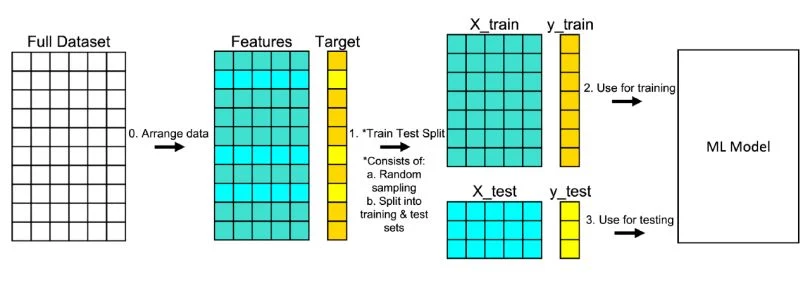

Now we implement the above using Sklearn's train_test_split module

In [ ]:
# keep all columns except the target! this will for our features often denoted X
X = df.drop('Approved', axis=1)
# keep only the target this will form of Target often denoted as y
y = df['Approved']


# now we split a 80/20 split repsectively so we now have to form X_train,X_test and y_train,y_test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

let us verify that the splits are as expected

In [ ]:
X_train.head()

,Income,Tax_Paid,Reliability_Score,Loan_Policy,Property,Credit
43,3980,597.00,0.518463,POL_2024,Rural,Good
50,6166,924.90,0.525049,POL_2024,Urban,Fair
95,1764,264.60,0.538532,POL_2024,Suburb,Poor
27,6393,958.95,0.443370,POL_2024,Suburb,Good
40,8241,1236.15,0.522746,POL_2024,Suburb,Fair


In [ ]:
X_train.shape

(80, 6)

In [ ]:
y_train

,Approved
43,1
50,1
95,0
27,1
40,1
...,...
60,1
24,0
75,1
30,0


In [ ]:
y_train.shape

(80,)

In [ ]:
X_test.head()

,Income,Tax_Paid,Reliability_Score,Loan_Policy,Property,Credit
84,2790,418.50,0.477654,POL_2024,Urban,Good
81,6310,946.50,0.414284,POL_2024,Rural,Poor
71,14423,2163.45,0.418419,POL_2024,Rural,Poor
67,9921,1488.15,0.689679,POL_2024,Urban,Good
94,3735,560.25,0.517318,POL_2024,Urban,Good


In [ ]:
X_test.shape

(20, 6)

In [ ]:
y_test

,Approved
84,1
81,1
71,1
67,1
94,1
2,1
99,0
15,0
79,1
72,0


In [ ]:
y_test.shape

(20,)

# Why Stratify?

train_test_split by default will randomly select rows from the dataframe - as a consequences there is a chance the target labels may be disproportionately present in either the training or test set not capturing the appropriate partition.

# What's with the random state?

if we call train test split without a random state it will retrieve a new set of rows for the X_train,X_test,y_train,y_test this is problematic because it is hard to tell where our model improvements to predictions can be attribute to our modelling effort of that we luckily got a 'good' slice of data



#  Removing Redundant & Unhelpful Features

In this step, we look for "Dead Weight."

* **Constant Features:** If a column never changes (like `Loan_Policy`), it provides no information. From the describe method we can Identify that Loan Policy occurs 80 times with a single value providing no explanatory power/signal at all

In [ ]:
# using include all allows us to also include categoricalb variables in .describe()
X_train.describe(include="all")

,Income,Tax_Paid,Reliability_Score,Loan_Policy,Property,Credit
count,80.000000,80.000000,80.000000,80,80,80
unique,NaN,NaN,NaN,1,3,3
top,NaN,NaN,NaN,POL_2024,Suburb,Good
freq,NaN,NaN,NaN,80,30,34
mean,5574.812500,836.221875,0.498231,NaN,NaN,NaN
std,3644.500372,546.675056,0.092231,NaN,NaN,NaN
min,785.000000,117.750000,0.308123,NaN,NaN,NaN
25%,3324.500000,498.675000,0.419312,NaN,NaN,NaN
50%,4388.000000,658.200000,0.513711,NaN,NaN,NaN
75%,6534.250000,980.137500,0.553817,NaN,NaN,NaN


* **Derivative Features:** Since `Tax_Paid` is a direct mathematical result of `Income`, it is perfectly correlated. Including it creates **Multicollinearity**, which can make our model unstable.

In [ ]:
# when one column derived exactly from another the result is 100% correlation
X_train[['Income','Tax_Paid','Reliability_Score']].corr()

,Income,Tax_Paid,Reliability_Score
Income,1.000000,1.000000,0.047343
Tax_Paid,1.000000,1.000000,0.047343
Reliability_Score,0.047343,0.047343,1.000000


In practice you perhaps wont always encounter such a clear example of collinearity

let proceed to remove highly correlated column but remember - we have to remove from both X_train and y_train for consistency

In [ ]:
# Identify and drop features with zero variance (constants)
X_train = X_train.drop(columns=["Loan_Policy"])
X_test = X_test.drop(columns=["Loan_Policy"])
print(f"Dropping Loan_Policy because it is a constant value")


Dropping Loan_Policy because it is a constant value


In [ ]:
# Dropping 'Tax_Paid' because it is a mathematical derivative of Income
X_train = X_train.drop(columns=['Tax_Paid'])
X_test = X_test.drop(columns=['Tax_Paid'])
print(f"Dropping Tax_Paid because it is a 100% correlated to Income")

Dropping Tax_Paid because it is a 100% correlated to Income


Lets verify that new X_train and X_test are as expected

In [ ]:
X_train.head()

,Income,Reliability_Score,Property,Credit
43,3980,0.518463,Rural,Good
50,6166,0.525049,Urban,Fair
95,1764,0.538532,Suburb,Poor
27,6393,0.443370,Suburb,Good
40,8241,0.522746,Suburb,Fair


In [ ]:
X_test.head()

,Income,Reliability_Score,Property,Credit
84,2790,0.477654,Urban,Good
81,6310,0.414284,Rural,Poor
71,14423,0.418419,Rural,Poor
67,9921,0.689679,Urban,Good
94,3735,0.517318,Urban,Good




##   Encoding (Text to Numbers)

Computers can't do math on text. We need to convert categories into numbers.

* **Ordinal Encoding:** For `Credit`, we map it to a rank () because "Good" is mathematically "higher" than "Poor."
* **One-Hot Encoding:** For `Property`, we create separate columns because "Urban" isn't "greater" than "Rural." Using `drop_first=True` avoids redundant data.

In [ ]:
# 1. Ordinal Mapping (Ranked data)
credit_map = {'Poor': 0, 'Fair': 1, 'Good': 2}
X_train['Credit'] = X_train['Credit'].map(credit_map)
X_test['Credit'] = X_test['Credit'].map(credit_map)

# 2. One-Hot Encoding (Non-ranked data)
X_train = pd.get_dummies(X_train, columns=['Property'], drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=['Property'], drop_first=True, dtype=int)

let us now look at the shape of our data

In [ ]:
X_train.head()

,Income,Reliability_Score,Credit,Property_Suburb,Property_Urban
43,3980,0.518463,2,0,0
50,6166,0.525049,1,0,1
95,1764,0.538532,0,1,0
27,6393,0.443370,2,1,0
40,8241,0.522746,1,1,0


In [ ]:
X_test.head()

,Income,Reliability_Score,Credit,Property_Suburb,Property_Urban
84,2790,0.477654,2,0,1
81,6310,0.414284,0,0,0
71,14423,0.418419,0,0,0
67,9921,0.689679,2,0,1
94,3735,0.517318,2,0,1


# New considerations: Feature scales and asymmetry

Most ML Algortithms with except of a view do not perform well if features are on different scales, they make arbritrarily deem a feature a more important simply because it has higher values than the rest. In particualr we present the ideal scenerio vs real life

Perfect CASE:
- all the features are on the same range
- all the features are symmetrical

Imperfect Case 1:
- feature has different range
- but it is symmmetrical

Imperfect Case 2:
- features have differing ranges
- some features are asymmetrical and exhibit longtailedness





## Handling Case 2 (Our Scenerio)


First let us inspect the distribution of the Income column we can observe that most values "squished" to the right of the distribution - clearly not symmetrical so this means we cannot use our of normalisation techniques right away

<Axes: title={'center': 'Income (Raw)'}, ylabel='Frequency'>

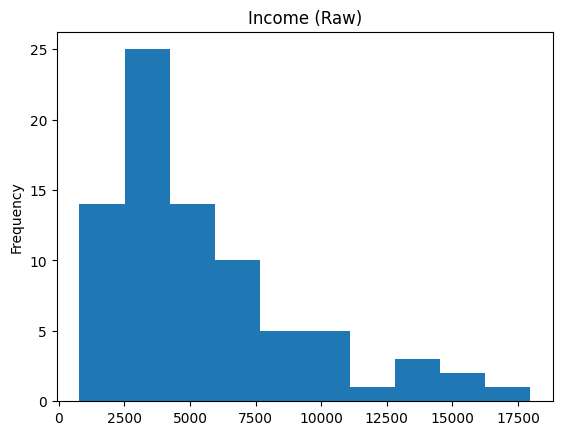

In [ ]:
X_train["Income"].plot(kind="hist", title="Income (Raw)")

further observer that compare to reliability score range of values are significantly higher

<Axes: title={'center': 'Income (Raw)'}, ylabel='Frequency'>

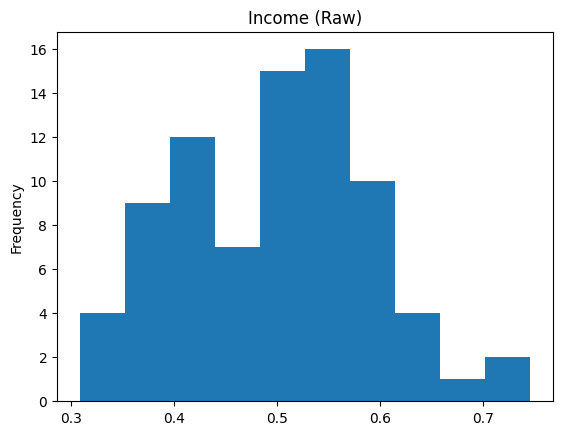

In [ ]:
X_train["Reliability_Score"].plot(kind="hist", title="Income (Raw)")

*Reliability score is roughly between 0-1

# Approach 1 - Bucketing

In this approach we convert the feature into a set of bins/group this approach is preferred when using model that benefit from informative groups e.g. decision trees

# Uniform Binning

<Axes: title={'center': 'Age (Uniform Binning)'}, xlabel='Income', ylabel='Frequency'>

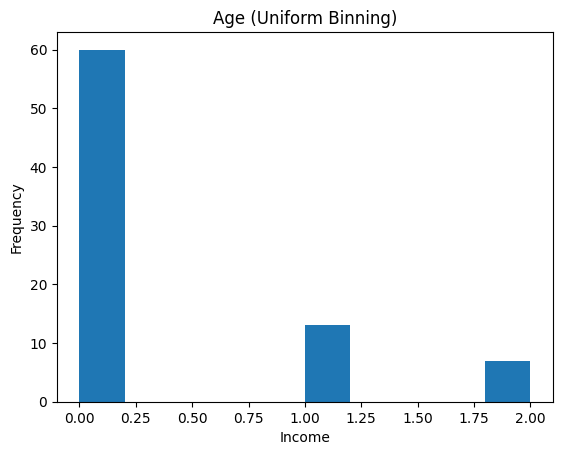

In [ ]:
# # Grouping Income into 3 buckets based on the training data range
# X_train['Income_Bin'] = pd.cut(X_train['Income'], bins=3, labels=[0, 1, 2]).astype(int)
# X_test['Income_Bin'] = pd.cut(X_test['Income'], bins=3, labels=[0, 1, 2]).astype(int)

binner = KBinsDiscretizer(n_bins=3, encode='ordinal', strategy='uniform')
binned_data = binner.fit_transform(X_train[['Income']])

pd.Series(binned_data.reshape(-1,)).plot(
    title='Age (Uniform Binning)', kind='hist', xlabel='Income'
)

In [ ]:
# This will show you the dollar amounts where one bin ends and the next begins
print(binner.bin_edges_)

[array([  785.,  6514., 12243., 17972.])]


# Quantile Binning

<Axes: title={'center': 'Age (Uniform Binning)'}, xlabel='Income', ylabel='Frequency'>

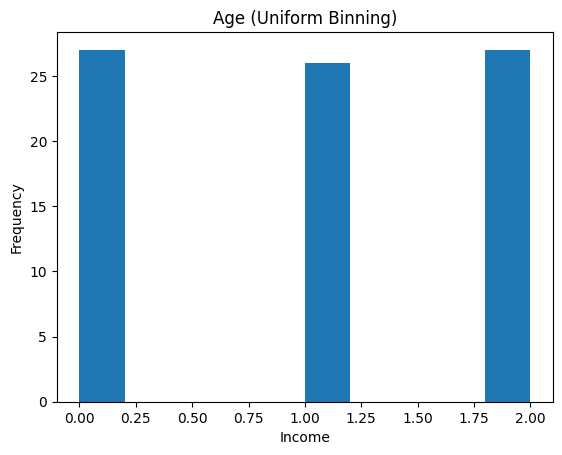

In [ ]:
binner = KBinsDiscretizer(n_bins=3, encode='ordinal', strategy='quantile')
binned_data = binner.fit_transform(X_train[['Income']])
pd.Series(binned_data.reshape(-1,)).plot(
    title='Age (Uniform Binning)', kind='hist', xlabel='Income'
)

In [ ]:
# This will show you the dollar amounts where one bin ends and the next begins
print(binner.bin_edges_)

[array([  785.,  3549.,  5971., 17972.])]


Based on the above, the quantile discretization method provide 'more meaningful' groups - so we will proceed with that one

In [ ]:
# For the Training Set
X_train['Income'] = binner.fit_transform(X_train[['Income']])

# For the Test Set
X_test['Income'] = binner.transform(X_test[['Income']])

Let us confirm inspection that discretized versions of the columsn have replaced the original

In [ ]:
X_train.head()

,Income,Property,Credit
43,1.0,Rural,Good
50,2.0,Urban,Fair
95,0.0,Suburb,Poor
27,2.0,Suburb,Good
40,2.0,Suburb,Fair


In [ ]:
X_test.head()

,Income,Property,Credit
84,0.0,Urban,Good
81,2.0,Rural,Poor
71,2.0,Rural,Poor
67,2.0,Urban,Good
94,1.0,Urban,Good


we can confirm that indeed the column above has now been discretized

In [ ]:
# note to self the last part is to divide by number of bins

# APPROACH 2



# Log Transformation

Machine learning models often perform best on symmetrical, bell-shaped data (**Gaussian distribution**). Because Income is usually "Right-Skewed" (most earn a little, a few earn a lot), we use a **Log Transform** to pull those high earners in and spread the distribution out.

In [ ]:
# Applying log(1+x) to normalize the income distribution
X_train['Income'] = np.log1p(X_train['Income'])
X_test['Income'] = np.log1p(X_test['Income'])

Distribution of Income After The Log Transform

<Axes: title={'center': 'Income (Log Transform)'}, ylabel='Frequency'>

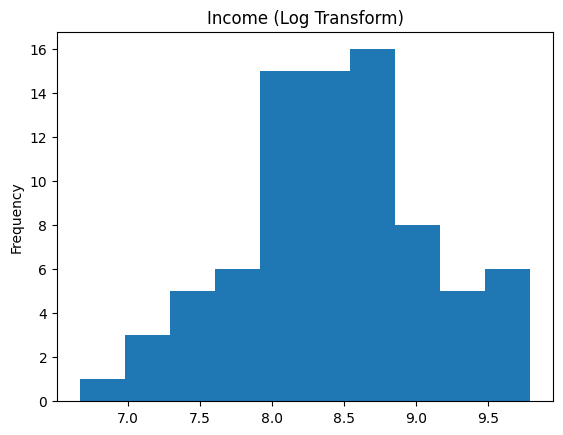

In [ ]:
X_train["Log_Income"].plot(kind="hist", title="Income (Log Transform)")

We can observe that the data is Markedly more centred and better aligned to be used by a model


# Scaling

This is our final step. Income might be around  while Credit is . **Standardization** shifts every column so they have a **Mean of 0** and a **Standard Deviation of 1**. This ensures the model treats every feature with equal mathematical weight.

In [ ]:
scaler = StandardScaler()

# Fit ONLY on X_train (calculate mean/std), then transform both
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print("\nSuccess! Your data is now model-ready.")
print(X_train_scaled.head())


Success! Your data is now model-ready.
     Income  Reliability_Score    Credit  Property_Suburb  Property_Urban  \
0 -0.218467           0.220745  1.022992        -0.774597       -0.693889   
1  0.465291           0.292602 -0.340997        -0.774597        1.441153   
2 -1.489160           0.439706 -1.704986         1.290994       -0.693889   
3  0.521762          -0.598577  1.022992         1.290994       -0.693889   
4  0.918386           0.267471 -0.340997         1.290994       -0.693889   

   Log_Income  
0   -0.218467  
1    0.465291  
2   -1.489160  
3    0.521762  
4    0.918386  


Teacher Note:
Min Max Normalization can be used instead but is better for algorithms that expect values between [-1,1] such as neural networks